- Simple End-to-End Warehouse Multi-Agent System Demo
- Uses LangGraph for agent workflow. Minimal, readable, and self-contained.

In [10]:
# Fresh import cell - all dependencies for the multi-agent system
from langgraph.graph import StateGraph, END
from langgraph.checkpoint.memory import MemorySaver

print("✅ All imports loaded successfully!")

✅ All imports loaded successfully!


In [11]:
# Add src directory to Python path
#sys.path.insert(0, os.path.join(os.path.dirname(__file__), 'src'))

# Minimal agent classes

In [12]:
class PickerRobot:
    def __init__(self, robot_id, zone_id):
        self.agent_id = f"picker_{robot_id}"
        self.zone_id = zone_id
        self.agent_type = "worker"
        self.capabilities = ["item_picking"]

    def process(self, state):
        print(f"[Picker {self.agent_id}] Picking items in zone {self.zone_id}")
        state['active_tasks'][self.agent_id] = 'picked'
        return state


class TransportRobot:
    def __init__(self, robot_id, zone_id):
        self.agent_id = f"transport_{robot_id}"
        self.zone_id = zone_id
        self.agent_type = "worker"
        self.capabilities = ["item_transport"]

    def process(self, state):
        print(
            f"[Transport {self.agent_id}] Transporting items in zone {self.zone_id}")
        state['active_tasks'][self.agent_id] = 'transported'
        return state


class ZoneSupervisor:
    def __init__(self, zone_id):
        self.agent_id = f"zone_sup_{zone_id}"
        self.zone_id = zone_id
        self.agent_type = "supervisor"

    def process(self, state):
        print(f"[ZoneSupervisor {self.zone_id}] Delegating tasks to workers")
        # For demo, just pass state to a worker
        next_worker = state.get('next_worker', f"picker_{self.zone_id}P1")
        state['next_agent'] = next_worker
        return state


class TopLevelSupervisor:
    def __init__(self):
        self.agent_id = "top_supervisor_main"
        self.agent_type = "supervisor"

    def process(self, state):
        print("[TopSupervisor] Assigning order to zone supervisor")
        # For demo, always send to zone_sup_A
        state['next_agent'] = 'zone_sup_A'
        return state

# Minimal state and workflow setup

In [13]:
def create_initial_state():
    return {
        'thread_id': 'demo-001',  # <-- Add this line
        'pending_orders': [{'order_id': 'ORD_001', 'items': [{'item_id': 'BOOK_001', 'quantity': 2}]}],
        'active_tasks': {},
        'next_agent': 'top_supervisor_main',
        'next_worker': 'picker_AP1',
    }

### 1. Create agents

In [14]:
agents = {
    'top_supervisor_main': TopLevelSupervisor(),
    'zone_sup_A': ZoneSupervisor('A'),
    'picker_AP1': PickerRobot('AP1', 'A'),
    'transport_AT1': TransportRobot('AT1', 'A'),
}

### 2. Build LangGraph workflow

In [15]:
workflow = StateGraph(dict)
for agent_id, agent in agents.items():
    workflow.add_node(agent_id, agent.process)
workflow.add_conditional_edges(
    'top_supervisor_main',
    lambda state: state['next_agent'],
    {'zone_sup_A': 'zone_sup_A'}
)
workflow.add_conditional_edges(
    'zone_sup_A',
    lambda state: state['next_agent'],
    {'picker_AP1': 'picker_AP1'}
)
workflow.add_edge('picker_AP1', 'transport_AT1')
workflow.add_edge('transport_AT1', END)
workflow.set_entry_point('top_supervisor_main')
agent_graph = workflow.compile(checkpointer=MemorySaver()) # checkpointer added

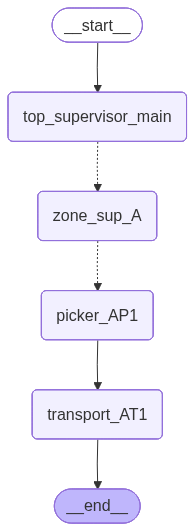

In [16]:
# Display the graph
from IPython.display import display, HTML, Image
display(Image(agent_graph.get_graph().draw_mermaid_png()))

### 3. Run simulation

In [17]:
print("\n🚀 Starting simple warehouse simulation...")
initial_state = create_initial_state()
for step, result in enumerate(
    agent_graph.stream(
        initial_state,
        stream_mode="values",
        config={"configurable": {"thread_id": initial_state["thread_id"]}}
    )
):
    print(f"Step {step+1}: {result['active_tasks']}")
print("\n✅ Simple warehouse workflow complete!")


🚀 Starting simple warehouse simulation...
Step 1: {}
[TopSupervisor] Assigning order to zone supervisor
Step 2: {}
[ZoneSupervisor A] Delegating tasks to workers
Step 3: {}
[Picker picker_AP1] Picking items in zone A
Step 4: {'picker_AP1': 'picked'}
[Transport transport_AT1] Transporting items in zone A
Step 5: {'picker_AP1': 'picked', 'transport_AT1': 'transported'}

✅ Simple warehouse workflow complete!
